In [1]:
import os
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_recall_fscore_support, accuracy_score
)
from sklearn.preprocessing import label_binarize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

import albumentations as A

print("✓ Libraries imported")

# Check GPU
print("\n[3/5] Checking GPU availability...")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ GPU Available: {gpus}")
    # Set memory growth
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("⚠ No GPU found. Training will be slow!")

print(f"✓ TensorFlow version: {tf.__version__}")

2025-10-12 11:28:49.447196: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760268529.678560      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760268529.750746      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


✓ Libraries imported

[3/5] Checking GPU availability...
✓ GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✓ TensorFlow version: 2.18.0


In [4]:
 !pip install ipywidgets --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 3.7 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 8.1.5
    Uninstalling ipywidgets-8.1.5:
      Successfully uninstalled ipywidgets-8.1.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
bigframes 2.12.0 requires google-cloud-bigquery[bqstorage,pandas]>=3.31.0, but you have google-cloud-bigquery 3.25.0 which is incompatible.
bigframes 2.12.0 requires rich<14,>=12.4.4, but you have rich 14.1.0 which is incompatible.


In [10]:
import os

# ==============================================================================
# SECTION 2: KAGGLE API SETUP
# ==============================================================================

print("\n[4/5] Setting up Kaggle API...")

# Create the .kaggle directory
!mkdir -p ~/.kaggle

# Your Kaggle API key as a string
# IMPORTANT: Be careful with sharing your notebook when keys are hardcoded.
kaggle_json_content = '{"username":"saivenkat123456","key":"8787b70036ef2de650019f9859bf5d6c"}'

# Write the key to the kaggle.json file
with open(os.path.expanduser("~/.kaggle/kaggle.json"), "w") as f:
    f.write(kaggle_json_content)

# Set the appropriate permissions for the file
!chmod 600 ~/.kaggle/kaggle.json

print("✓ Kaggle API configured")


# ==============================================================================
# SECTION 3: DIRECTORY CREATION
# ==============================================================================

print("\n[5/5] Creating directories...")
!mkdir -p /kaggle/working/datasets
!mkdir -p /kaggle/working/models
!mkdir -p /kaggle/working/results
print("✓ Directories created")

print("\n" + "="*80)
print("SETUP COMPLETE!")
print("="*80)


[4/5] Setting up Kaggle API...
✓ Kaggle API configured

[5/5] Creating directories...
✓ Directories created

SETUP COMPLETE!


In [16]:
import os

# ==============================================================================
# SECTION 3: DOWNLOAD DATASETS (Corrected for Kaggle)
# ==============================================================================

print("\n" + "="*80)
print("DOWNLOADING DATASETS")
print("="*80)

# Define the base path for Kaggle's working directory
KAGGLE_DATASETS_PATH = "/kaggle/working/datasets"
os.makedirs(KAGGLE_DATASETS_PATH, exist_ok=True)


# Download Dataset-101
print("\n[1/2] Downloading Dataset-101...")
# Changed path from /content/datasets to KAGGLE_DATASETS_PATH
!kaggle datasets download -d dhirajmwagh1111/dataset-for-different-eye-disease -p {KAGGLE_DATASETS_PATH}
!unzip -q {KAGGLE_DATASETS_PATH}/dataset-for-different-eye-disease.zip -d {KAGGLE_DATASETS_PATH}/dataset101
!rm {KAGGLE_DATASETS_PATH}/dataset-for-different-eye-disease.zip
print("✓ Dataset-101 downloaded")

# Download Retinal OCT-C8
print("\n[2/2] Downloading Retinal OCT-C8...")
# Changed path from /content/datasets to KAGGLE_DATASETS_PATH
!kaggle datasets download -d obulisainaren/retinal-oct-c8 -p {KAGGLE_DATASETS_PATH}
!unzip -q {KAGGLE_DATASETS_PATH}/retinal-oct-c8.zip -d {KAGGLE_DATASETS_PATH}/
!rm {KAGGLE_DATASETS_PATH}/retinal-oct-c8.zip
print("✓ Retinal OCT-C8 downloaded")

# Verify dataset structure
print("\n" + "="*80)
print("VERIFYING DATASET STRUCTURE")
print("="*80)

def verify_and_display_structure():
    
    # Dataset-101
    # Changed path from /content/ to /kaggle/working/
    dataset101_path = '/kaggle/working/datasets/dataset101'
    if os.path.exists(dataset101_path):
        print("\n✓ Dataset-101 found:")
        # The dataset has an extra nested folder, let's adjust the path
        # Common structure is /dataset101/Eye_Disease_Dataset/train
        potential_train_path = os.path.join(dataset101_path, 'Eye_Disease_Dataset', 'train')
        if not os.path.exists(potential_train_path):
            potential_train_path = os.path.join(dataset101_path, 'train') # Fallback
            
        if os.path.exists(potential_train_path):
            classes = sorted([d for d in os.listdir(potential_train_path) 
                              if os.path.isdir(os.path.join(potential_train_path, d))])
            print(f"  Location: {dataset101_path}")
            print(f"  Classes ({len(classes)}): {classes}")
            total_images = sum([len(os.listdir(os.path.join(potential_train_path, c))) 
                                for c in classes])
            print(f"  Total images: {total_images}")
        else:
            print(f"✗ 'train' directory not found inside {dataset101_path}!")
    else:
        print("✗ Dataset-101 not found!")
    
    # Retinal OCT-C8
    # Changed path from /content/ to /kaggle/working/
    retinal_path = '/kaggle/working/datasets/RetinalOCT_Dataset'
    if os.path.exists(retinal_path):
        print("\n✓ Retinal OCT-C8 found:")
        print(f"  Location: {retinal_path}")
        
        for split in ['train', 'val', 'test']:
            split_path = os.path.join(retinal_path, split)
            if os.path.exists(split_path):
                classes = sorted([d for d in os.listdir(split_path) 
                                  if os.path.isdir(os.path.join(split_path, d))])
                total_images = sum([len(os.listdir(os.path.join(split_path, c))) 
                                    for c in classes])
                print(f"  {split.upper()}: {total_images} images across {len(classes)} classes")
                if split == 'train':
                    print(f"  Classes: {classes}")
    else:
        print("✗ Retinal OCT-C8 not found!")

verify_and_display_structure()

print("\n" + "="*80)
print("DATASETS READY!")
print("="*80)


DOWNLOADING DATASETS

[1/2] Downloading Dataset-101...
Dataset URL: https://www.kaggle.com/datasets/dhirajmwagh1111/dataset-for-different-eye-disease
License(s): other
 95%|████████████████████████████████████▏ | 2.23G/2.34G [00:01<00:00, 1.25GB/s]
100%|██████████████████████████████████████| 2.34G/2.34G [00:02<00:00, 1.25GB/s]
✓ Dataset-101 downloaded

[2/2] Downloading Retinal OCT-C8...
Dataset URL: https://www.kaggle.com/datasets/obulisainaren/retinal-oct-c8
License(s): CC-BY-NC-SA-4.0
 99%|█████████████████████████████████████▌| 1.40G/1.42G [00:01<00:00, 1.24GB/s]
100%|██████████████████████████████████████| 1.42G/1.42G [00:01<00:00, 1.24GB/s]
✓ Retinal OCT-C8 downloaded

VERIFYING DATASET STRUCTURE

✓ Dataset-101 found:
✗ 'train' directory not found inside /kaggle/working/datasets/dataset101!

✓ Retinal OCT-C8 found:
  Location: /kaggle/working/datasets/RetinalOCT_Dataset

DATASETS READY!


In [17]:
# ==============================================================================
# SECTION 4: DATA PREPROCESSING & AUGMENTATION
# ==============================================================================

print("\n" + "="*80)
print("BUILDING DATA PIPELINE")
print("="*80)

class MemoryEfficientDataGenerator(keras.utils.Sequence):
    """Memory-efficient data generator with medical image augmentation"""
    
    def __init__(self, image_paths, labels, batch_size=16, 
                 img_size=(224, 224), augment=True, shuffle=True):
        self.image_paths = image_paths
        self.labels = labels
        self.batch_size = batch_size
        self.img_size = img_size
        self.augment = augment
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.image_paths))
        self.on_epoch_end()
        
        # Advanced medical image augmentation
        self.augmentor = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Rotate(limit=20, p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
            A.CLAHE(clip_limit=2.0, p=0.3),
            A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),
            A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=15, p=0.5),
            A.OneOf([
                A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=1),
                A.GridDistortion(num_steps=5, distort_limit=0.3, p=1),
                A.OpticalDistortion(distort_limit=0.5, shift_limit=0.5, p=1),
            ], p=0.2),
        ])
    
    def __len__(self):
        return int(np.ceil(len(self.image_paths) / self.batch_size))
    
    def __getitem__(self, index):
        indexes = self.indexes[index*self.batch_size:(index+1)*self.batch_size]
        batch_paths = [self.image_paths[i] for i in indexes]
        batch_labels = [self.labels[i] for i in indexes]
        X, y = self.__data_generation(batch_paths, batch_labels)
        return X, y
    
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)
    
    def __data_generation(self, batch_paths, batch_labels):
        X = np.empty((len(batch_paths), *self.img_size, 3), dtype=np.float32)
        y = np.array(batch_labels)
        
        for i, path in enumerate(batch_paths):
            img = cv2.imread(path)
            if img is None:
                img = np.zeros((*self.img_size, 3), dtype=np.uint8)
            else:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, self.img_size)
            
            if self.augment:
                try:
                    augmented = self.augmentor(image=img)
                    img = augmented['image']
                except:
                    pass  # If augmentation fails, use original
            
            X[i] = img / 255.0
        
        return X, y

def load_dataset_paths(dataset_path, dataset_type='dataset101'):
    """Load image paths and labels from dataset"""
    image_paths = []
    labels = []
    class_names = []
    
    if dataset_type == 'dataset101':
        train_path = os.path.join(dataset_path, 'train')
        if os.path.exists(train_path):
            class_names = sorted([d for d in os.listdir(train_path) 
                                if os.path.isdir(os.path.join(train_path, d))])
            for class_idx, class_name in enumerate(class_names):
                class_path = os.path.join(train_path, class_name)
                for img_name in os.listdir(class_path):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        image_paths.append(os.path.join(class_path, img_name))
                        labels.append(class_idx)
    
    elif dataset_type == 'retinal_c8':
        # Use train, val, and test splits
        for split in ['train', 'val', 'test']:
            split_path = os.path.join(dataset_path, split)
            if os.path.exists(split_path):
                if not class_names:  # Get class names from first split
                    class_names = sorted([d for d in os.listdir(split_path) 
                                        if os.path.isdir(os.path.join(split_path, d))])
                
                for class_idx, class_name in enumerate(class_names):
                    class_path = os.path.join(split_path, class_name)
                    if os.path.exists(class_path):
                        for img_name in os.listdir(class_path):
                            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                                image_paths.append(os.path.join(class_path, img_name))
                                labels.append(class_idx)
    
    return np.array(image_paths), np.array(labels), class_names

print("\n✓ Data pipeline built successfully!")



BUILDING DATA PIPELINE

✓ Data pipeline built successfully!


In [21]:
# Define the base path for easier access
DATASET_PATH="/kaggle/working/datasets/dataset101/DATASET_101"

# Rename the directories from uppercase to lowercase
!mv "$DATASET_PATH/Train" "$DATASET_PATH/train"
!mv "$DATASET_PATH/Test" "$DATASET_PATH/test"

# Verify the change
!ls "$DATASET_PATH"

test  train


In [22]:
# ==============================================================================
# SECTION 5: LOAD DATASET (Corrected for Kaggle)
# ==============================================================================

import gc
from sklearn.model_selection import train_test_split

print("\n" + "="*80)
print("LOADING DATASET")
print("="*80)

# Choose dataset to work with
DATASET_CHOICE = 'dataset101'  # Options: 'dataset101' or 'retinal_c8'

if DATASET_CHOICE == 'dataset101':
    print("\nLoading Dataset-101...")
    # Corrected the path to point to the actual data folder
    X_paths, y_labels, class_names = load_dataset_paths(
        '/kaggle/working/datasets/dataset101/DATASET_101', 
        'dataset101'
    )
    DATASET_NAME = "Dataset-101"
    
elif DATASET_CHOICE == 'retinal_c8':
    print("\nLoading Retinal OCT-C8...")
    # Corrected the path to point to the actual data folder
    X_paths, y_labels, class_names = load_dataset_paths(
        '/kaggle/working/datasets/RetinalOCT_Dataset/RetinalOCT_Dataset', 
        'retinal_c8'
    )
    DATASET_NAME = "Retinal OCT-C8"

print(f"\n✓ {DATASET_NAME} loaded successfully!")
print(f"  Total images: {len(X_paths)}")
print(f"  Number of classes: {len(class_names)}")
print(f"  Classes: {class_names}")

# Split data: 80% train, 10% val, 10% test
print("\nSplitting data...")
X_train_paths, X_temp_paths, y_train, y_temp = train_test_split(
    X_paths, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

X_val_paths, X_test_paths, y_val, y_test = train_test_split(
    X_temp_paths, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"✓ Data split complete:")
print(f"  Training: {len(X_train_paths)} images")
print(f"  Validation: {len(X_val_paths)} images")
print(f"  Testing: {len(X_test_paths)} images")

# Clear memory
gc.collect()


LOADING DATASET

Loading Dataset-101...

✓ Dataset-101 loaded successfully!
  Total images: 8429
  Number of classes: 6
  Classes: ['ACRIMA', 'Glaucoma', 'ODIR-5K', 'ORIGA', 'cataract', 'retina_disease']

Splitting data...
✓ Data split complete:
  Training: 6743 images
  Validation: 843 images
  Testing: 843 images


198

In [23]:
# ==============================================================================
# SECTION 6: ATTENTION MECHANISMS
# ==============================================================================

print("\n" + "="*80)
print("BUILDING ATTENTION MECHANISMS")
print("="*80)

class ChannelAttention(layers.Layer):
    """Channel Attention Module"""
    def __init__(self, ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
    
    def build(self, input_shape):
        channels = input_shape[-1]
        self.shared_dense1 = layers.Dense(channels // self.ratio, activation='relu')
        self.shared_dense2 = layers.Dense(channels, activation='sigmoid')
        super().build(input_shape)
    
    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=[1, 2], keepdims=True)
        
        avg_out = self.shared_dense2(self.shared_dense1(avg_pool))
        max_out = self.shared_dense2(self.shared_dense1(max_pool))
        
        attention = avg_out + max_out
        return inputs * attention
    
    def get_config(self):
        config = super().get_config()
        config.update({"ratio": self.ratio})
        return config

class SpatialAttention(layers.Layer):
    """Spatial Attention Module"""
    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
    
    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding='same', activation='sigmoid')
        super().build(input_shape)
    
    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        attention = self.conv(concat)
        return inputs * attention
    
    def get_config(self):
        config = super().get_config()
        config.update({"kernel_size": self.kernel_size})
        return config

print("✓ Attention mechanisms defined")


BUILDING ATTENTION MECHANISMS
✓ Attention mechanisms defined


In [24]:
# ==============================================================================
# SECTION 7: ENHANCED MODEL ARCHITECTURE
# ==============================================================================

print("\n" + "="*80)
print("BUILDING ENHANCED MODEL")
print("="*80)

def conv_block_enhanced(x, filters, stride=2, use_attention=True):
    """Enhanced convolutional block with attention"""
    x_skip = x
    
    # Main path
    x = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    x = layers.Conv2D(filters, 3, strides=1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    
    # Attention
    if use_attention:
        x = ChannelAttention()(x)
        x = SpatialAttention()(x)
    
    # Skip connection
    x_skip = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(x_skip)
    x_skip = layers.BatchNormalization()(x_skip)
    
    x = layers.Add()([x, x_skip])
    x = layers.Activation('relu')(x)
    
    return x

def identity_block_enhanced(x, filters, use_attention=True):
    """Enhanced identity block with attention"""
    x_skip = x
    
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    
    # Attention
    if use_attention:
        x = ChannelAttention()(x)
        x = SpatialAttention()(x)
    
    x = layers.Add()([x, x_skip])
    x = layers.Activation('relu')(x)
    
    return x

def build_enhanced_model(input_shape=(224, 224, 3), num_classes=6, model_name="Enhanced_Eye_Disease_Detector"):
    """
    Build enhanced multi-stage model with:
    - Attention mechanisms (Channel + Spatial)
    - Dual-branch architecture
    - Bidirectional LSTM
    - Advanced regularization
    """
    inputs = layers.Input(shape=input_shape, name='input_layer')
    
    # ============ STAGE 1: Grain Feature Extraction ============
    x = layers.Conv2D(64, 3, strides=2, padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    stage1_output = x
    
    # ============ STAGE 2: Dual-Branch Feature Enhancement ============
    
    # Branch 1: Deep feature extraction (long-range dependencies)
    branch1 = conv_block_enhanced(stage1_output, 128, stride=2)
    branch1 = identity_block_enhanced(branch1, 128)
    branch1 = identity_block_enhanced(branch1, 128)
    
    branch1 = conv_block_enhanced(branch1, 256, stride=2)
    branch1 = identity_block_enhanced(branch1, 256)
    branch1 = identity_block_enhanced(branch1, 256)
    branch1 = identity_block_enhanced(branch1, 256)
    
    branch1 = layers.GlobalAveragePooling2D(name='branch1_gap')(branch1)
    
    # Branch 2: Shallow feature extraction (short-range dependencies)
    branch2 = conv_block_enhanced(stage1_output, 128, stride=2)
    branch2 = identity_block_enhanced(branch2, 128)
    branch2 = identity_block_enhanced(branch2, 128)
    
    branch2 = layers.GlobalAveragePooling2D(name='branch2_gap')(branch2)
    
    # Feature Fusion
    fused_features = layers.Concatenate(name='feature_fusion')([branch1, branch2])
    fused_features = layers.Dropout(0.4)(fused_features)
    
    # ============ STAGE 3: Classification Module ============
    
    # Reshape for LSTM
    x = layers.Reshape((1, fused_features.shape[-1]))(fused_features)
    
    # Bidirectional LSTM
    x = layers.Bidirectional(layers.LSTM(256, return_sequences=False), name='bilstm')(x)
    x = layers.Dropout(0.5)(x)
    
    # Dense layers with regularization
    x = layers.Dense(512, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.3)(x)
    
    # Output layer
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name=model_name)
    
    return model

# Build model
print("\nBuilding model...")
model = build_enhanced_model(
    input_shape=(224, 224, 3),
    num_classes=len(class_names),
    model_name=f"Enhanced_{DATASET_NAME.replace(' ', '_')}_Model"
)

# Display model summary
print("\n" + "="*80)
print("MODEL ARCHITECTURE")
print("="*80)
model.summary()

total_params = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])

print(f"\n✓ Model built successfully!")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size: ~{total_params * 4 / (1024**2):.2f} MB")

# Clear memory
gc.collect()



BUILDING ENHANCED MODEL

Building model...


I0000 00:00:1760270286.232948      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1760270286.233771      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



MODEL ARCHITECTURE


Model: "Enhanced_Dataset-101_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      1,728 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │     73,728 │ activation[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │    147,456 │ activation_1[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention   │ (None, 56, 56,    │      4,240 │ batch_normalizat… │
│ (ChannelAttention)  │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      8,192 │ activation[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_attention   │ (None, 56, 56,    │         99 │ channel_attentio… │
│ (SpatialAttention)  │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ spatial_attentio… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    147,456 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_5[0][0]  

 Total params: 7,914,628 (30.19 MB)

 Trainable params: 7,906,308 (30.16 MB)

 Non-trainable params: 8,320 (32.50 KB)


✓ Model built successfully!
  Total parameters: 7,914,628
  Trainable parameters: 7,906,308
  Model size: ~30.19 MB


1995

In [25]:
# ==============================================================================
# SECTION 8: PREPARE DATA GENERATORS
# ==============================================================================

print("\n" + "="*80)
print("PREPARING DATA GENERATORS")
print("="*80)

BATCH_SIZE = 16  # Optimized for Colab
IMG_SIZE = (224, 224)

print(f"\nConfiguration:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Image size: {IMG_SIZE}")
print(f"  Augmentation: Enabled for training")

# Create generators
train_gen = MemoryEfficientDataGenerator(
    X_train_paths, y_train,
    batch_size=BATCH_SIZE,
    img_size=IMG_SIZE,
    augment=True,
    shuffle=True
)

val_gen = MemoryEfficientDataGenerator(
    X_val_paths, y_val,
    batch_size=BATCH_SIZE,
    img_size=IMG_SIZE,
    augment=False,
    shuffle=False
)

test_gen = MemoryEfficientDataGenerator(
    X_test_paths, y_test,
    batch_size=BATCH_SIZE,
    img_size=IMG_SIZE,
    augment=False,
    shuffle=False
)

print(f"\n✓ Data generators created:")
print(f"  Train batches: {len(train_gen)}")
print(f"  Validation batches: {len(val_gen)}")
print(f"  Test batches: {len(test_gen)}")


PREPARING DATA GENERATORS

Configuration:
  Batch size: 16
  Image size: (224, 224)
  Augmentation: Enabled for training

✓ Data generators created:
  Train batches: 422
  Validation batches: 53
  Test batches: 53


/tmp/ipykernel_37/1679971638.py:30: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),
/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_37/1679971638.py:33: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=1),
/tmp/ipykernel_37/1679971638.py:35: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  A.OpticalDistortion(distort_limit=0.5, shift_limit=0.5, p=1),


In [ ]:
# ==============================================================================
# SECTION 9: TRAINING CONFIGURATION (Corrected for Kaggle)
# ==============================================================================

print("\n" + "="*80)
print("CONFIGURING TRAINING")
print("="*80)

# (lr_schedule function remains the same)
def lr_schedule(epoch, lr):
    """Custom learning rate schedule"""
    if epoch < 10:
        return lr
    elif epoch < 30:
        return lr * 0.5
    elif epoch < 50:
        return lr * 0.1
    else:
        return lr * 0.01

# Callbacks with corrected paths for Kaggle
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1,
        mode='min'
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1,
        mode='min'
    ),
    ModelCheckpoint(
        # Corrected path for Kaggle
        f'/kaggle/working/models/best_model_{DATASET_CHOICE}.h5',
        monitor='val_accuracy',
        save_best_only=True,
        save_weights_only=False,
        verbose=1,
        mode='max'
    ),
    CSVLogger(f'/kaggle/working/results/training_log_{DATASET_CHOICE}.csv'), # Corrected path
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=1)
]

# Compile model
# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=SparseCategoricalCrossentropy(),
    metrics=[
        'accuracy',
        # FIX: Use the sparse version of the metric
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_accuracy')
    ]
)

print("✓ Model compiled successfully!")

print("✓ Model compiled successfully!")
print("\nTraining configuration:")
print(f"  Optimizer: Adam (lr=0.001)")
print(f"  Loss: Sparse Categorical Crossentropy") # Updated description
print(f"  Metrics: Accuracy, Top-3 Accuracy")
print(f"  Callbacks: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger, LRScheduler")


CONFIGURING TRAINING
✓ Model compiled successfully!
✓ Model compiled successfully!

Training configuration:
  Optimizer: Adam (lr=0.001)
  Loss: Sparse Categorical Crossentropy
  Metrics: Accuracy, Top-3 Accuracy
  Callbacks: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger, LRScheduler


In [30]:
# ==============================================================================
# SECTION 10: TRAIN MODEL (Corrected for Kaggle)
# ==============================================================================
import gc
import tensorflow as tf

print("\n" + "="*80)
print("STARTING TRAINING")
print("="*80)

EPOCHS = 100
print(f"\nDataset: {DATASET_NAME}")
print(f"Classes: {len(class_names)}")
print(f"Max Epochs: {EPOCHS}")
print(f"Training samples: {len(X_train_paths)}")
print(f"Validation samples: {len(X_val_paths)}")
print("\n" + "="*80)

# Train model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "="*80)
print("TRAINING COMPLETED!")
print("="*80)

# Save final model
# FIX: Changed path from /content/ to /kaggle/working/
final_model_path = f'/kaggle/working/models/final_model_{DATASET_CHOICE}.h5'
model.save(final_model_path)
print(f"\n✓ Final model saved to: {final_model_path}")

# Save model weights separately
# FIX: Changed path from /content/ to /kaggle/working/
weights_path = f'/kaggle/working/models/final_weights_{DATASET_CHOICE}.weights.h5'
model.save_weights(weights_path)
print(f"✓ Model weights saved to: {weights_path}")

# Clear memory
gc.collect()
tf.keras.backend.clear_session()


STARTING TRAINING

Dataset: Dataset-101
Classes: 6
Max Epochs: 100
Training samples: 6743
Validation samples: 843


Epoch 1: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 1/100


I0000 00:00:1760270724.014901     184 cuda_dnn.cc:529] Loaded cuDNN version 90300


422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.8431 - loss: 3.3214 - top3_accuracy: 0.9574
Epoch 1: val_accuracy improved from -inf to 0.89205, saving model to /kaggle/working/models/best_model_dataset101.h5
422/422 ━━━━━━━━━━━━━━━━━━━━ 222s 433ms/step - accuracy: 0.8432 - loss: 3.3173 - top3_accuracy: 0.9574 - val_accuracy: 0.8921 - val_loss: 0.5583 - val_top3_accuracy: 0.9834 - learning_rate: 0.0010

Epoch 2: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.8836 - loss: 0.4987 - top3_accuracy: 0.9750
Epoch 2: val_accuracy improved from 0.89205 to 0.89561, saving model to /kaggle/working/models/best_model_dataset101.h5
422/422 ━━━━━━━━━━━━━━━━━━━━ 174s 411ms/step - accuracy: 0.8836 - loss: 0.4986 - top3_accuracy: 0.9750 - val_accuracy: 0.8956 - val_loss: 0.5724 - val_top3_accuracy: 0.9739 - learning_rate: 0.0010

Epoch 3: LearningRateScheduler setting learning rate to 0.0010000000474974

In [32]:
import tensorflow as tf
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# ==============================================================================
# SECTION 11: EVALUATION (Corrected for Kaggle)
# ==============================================================================

print("\n" + "="*80)
print("EVALUATING MODEL")
print("="*80)

# Load best model
# FIX: Changed path from /content/ to /kaggle/working/
best_model_path = f'/kaggle/working/models/best_model_{DATASET_CHOICE}.h5'
best_model = tf.keras.models.load_model(
    best_model_path,
    custom_objects={
        'ChannelAttention': ChannelAttention,
        'SpatialAttention': SpatialAttention
    }
)
print(f"✓ Best model loaded from: {best_model_path}")

# Evaluate on test set
print("\nEvaluating on test set...")
test_results = best_model.evaluate(test_gen, verbose=1)
test_loss = test_results[0]
test_acc = test_results[1]
test_top3 = test_results[2]

print("\n" + "="*80)
print(f"TEST RESULTS - {DATASET_NAME}")
print("="*80)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Top-3 Accuracy: {test_top3*100:.2f}%")
print("="*80)

# Generate predictions
print("\nGenerating predictions...")
y_pred_probs = best_model.predict(test_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification report
print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)
# Note: The y_test from your data split needs to match the test_gen order.
# Keras generators can sometimes shuffle data unless explicitly told not to.
# Assuming test_gen is not shuffled, this will work.
report = classification_report(
    y_test, y_pred,
    target_names=class_names,
    digits=4
)
print(report)

# Save classification report
report_dict = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
# FIX: Changed path from /content/ to /kaggle/working/
report_path = f'/kaggle/working/results/classification_report_{DATASET_CHOICE}.csv'
report_df.to_csv(report_path)
print(f"\n✓ Report saved to: {report_path}")


EVALUATING MODEL
✓ Best model loaded from: /kaggle/working/models/best_model_dataset101.h5

Evaluating on test set...
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 300ms/step - accuracy: 0.9644 - loss: 0.1755 - top3_accuracy: 0.9864

TEST RESULTS - Dataset-101
Test Loss: 0.1889
Test Accuracy: 95.61%
Test Top-3 Accuracy: 98.46%

Generating predictions...
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 321ms/step

CLASSIFICATION REPORT
                precision    recall  f1-score   support

        ACRIMA     0.9825    1.0000    0.9912        56
      Glaucoma     0.0000    0.0000    0.0000        21
       ODIR-5K     0.9695    0.9986    0.9838       700
         ORIGA     0.7846    0.9808    0.8718        52
      cataract     0.0000    0.0000    0.0000         7
retina_disease     0.0000    0.0000    0.0000         7

      accuracy                         0.9561       843
     macro avg     0.4561    0.4966    0.4745       843
  weighted avg     0.9187    0.9561    0.9365       843


✓ Report saved to: /kaggle/wo

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classif


GENERATING VISUALIZATIONS

[1/4] Creating confusion matrix...


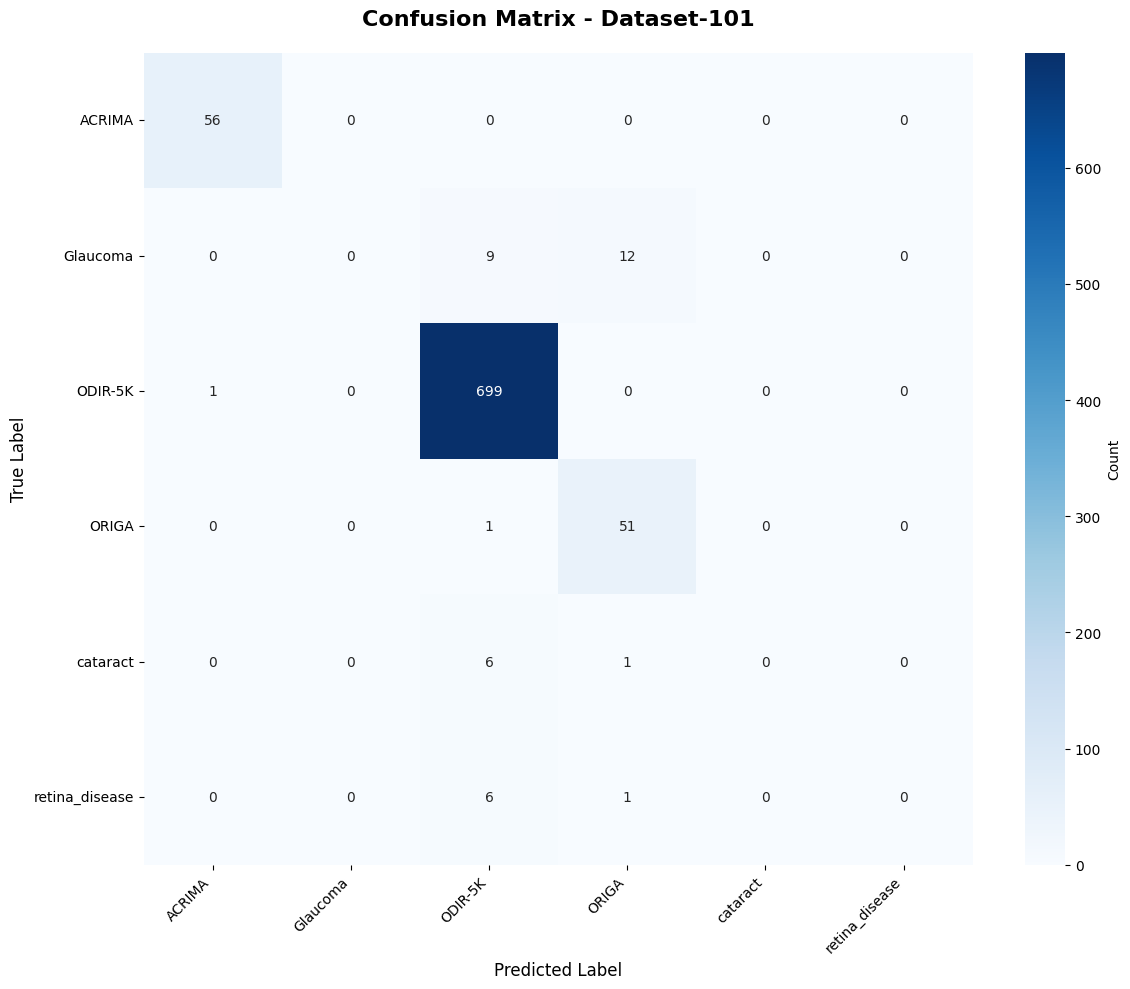

✓ Confusion matrix saved to: /content/results/confusion_matrix_dataset101.png


In [33]:
# ==============================================================================
# SECTION 12: VISUALIZATION - CONFUSION MATRIX
# ==============================================================================

print("\n" + "="*80)
print("GENERATING VISUALIZATIONS")
print("="*80)

# Confusion Matrix
print("\n[1/4] Creating confusion matrix...")
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title(f'Confusion Matrix - {DATASET_NAME}', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
cm_path = f'/content/results/confusion_matrix_{DATASET_CHOICE}.png'
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Confusion matrix saved to: {cm_path}")


[2/4] Creating ROC curves...


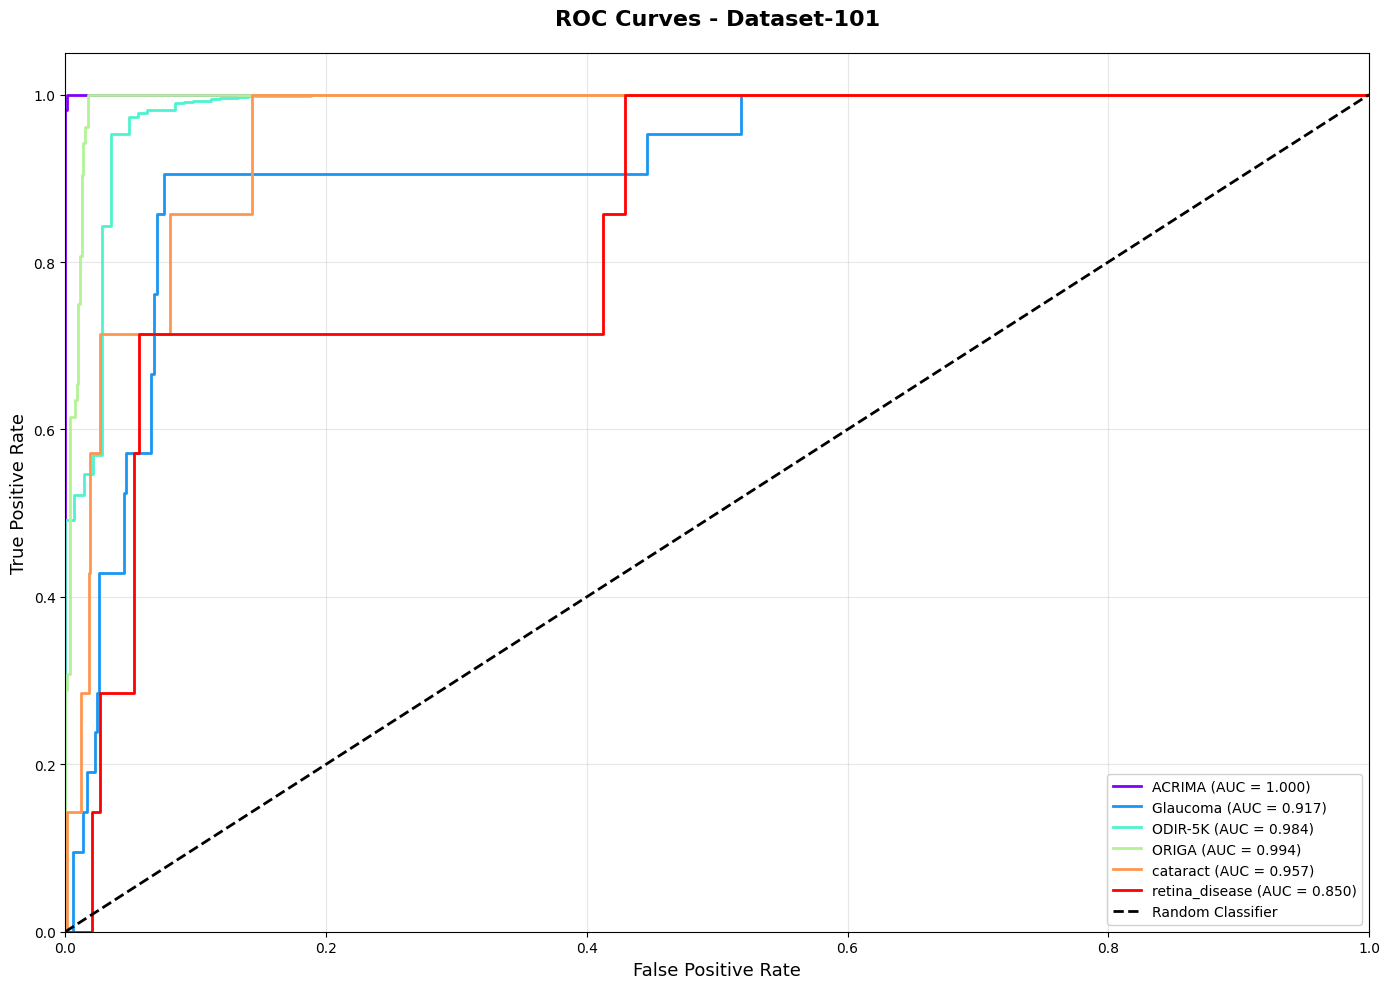

✓ ROC curves saved to: /content/results/roc_curves_dataset101.png


In [34]:
# ==============================================================================
# SECTION 13: VISUALIZATION - ROC CURVES
# ==============================================================================

print("\n[2/4] Creating ROC curves...")
n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

plt.figure(figsize=(14, 10))
colors = plt.cm.rainbow(np.linspace(0, 1, n_classes))

roc_auc_scores = {}
for i, (color, class_name) in enumerate(zip(colors, class_names)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    roc_auc_scores[class_name] = roc_auc
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{class_name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title(f'ROC Curves - {DATASET_NAME}', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc='lower right', fontsize=10, framealpha=0.9)
plt.grid(alpha=0.3)
plt.tight_layout()
roc_path = f'/content/results/roc_curves_{DATASET_CHOICE}.png'
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ ROC curves saved to: {roc_path}")



[3/4] Creating training history plots...


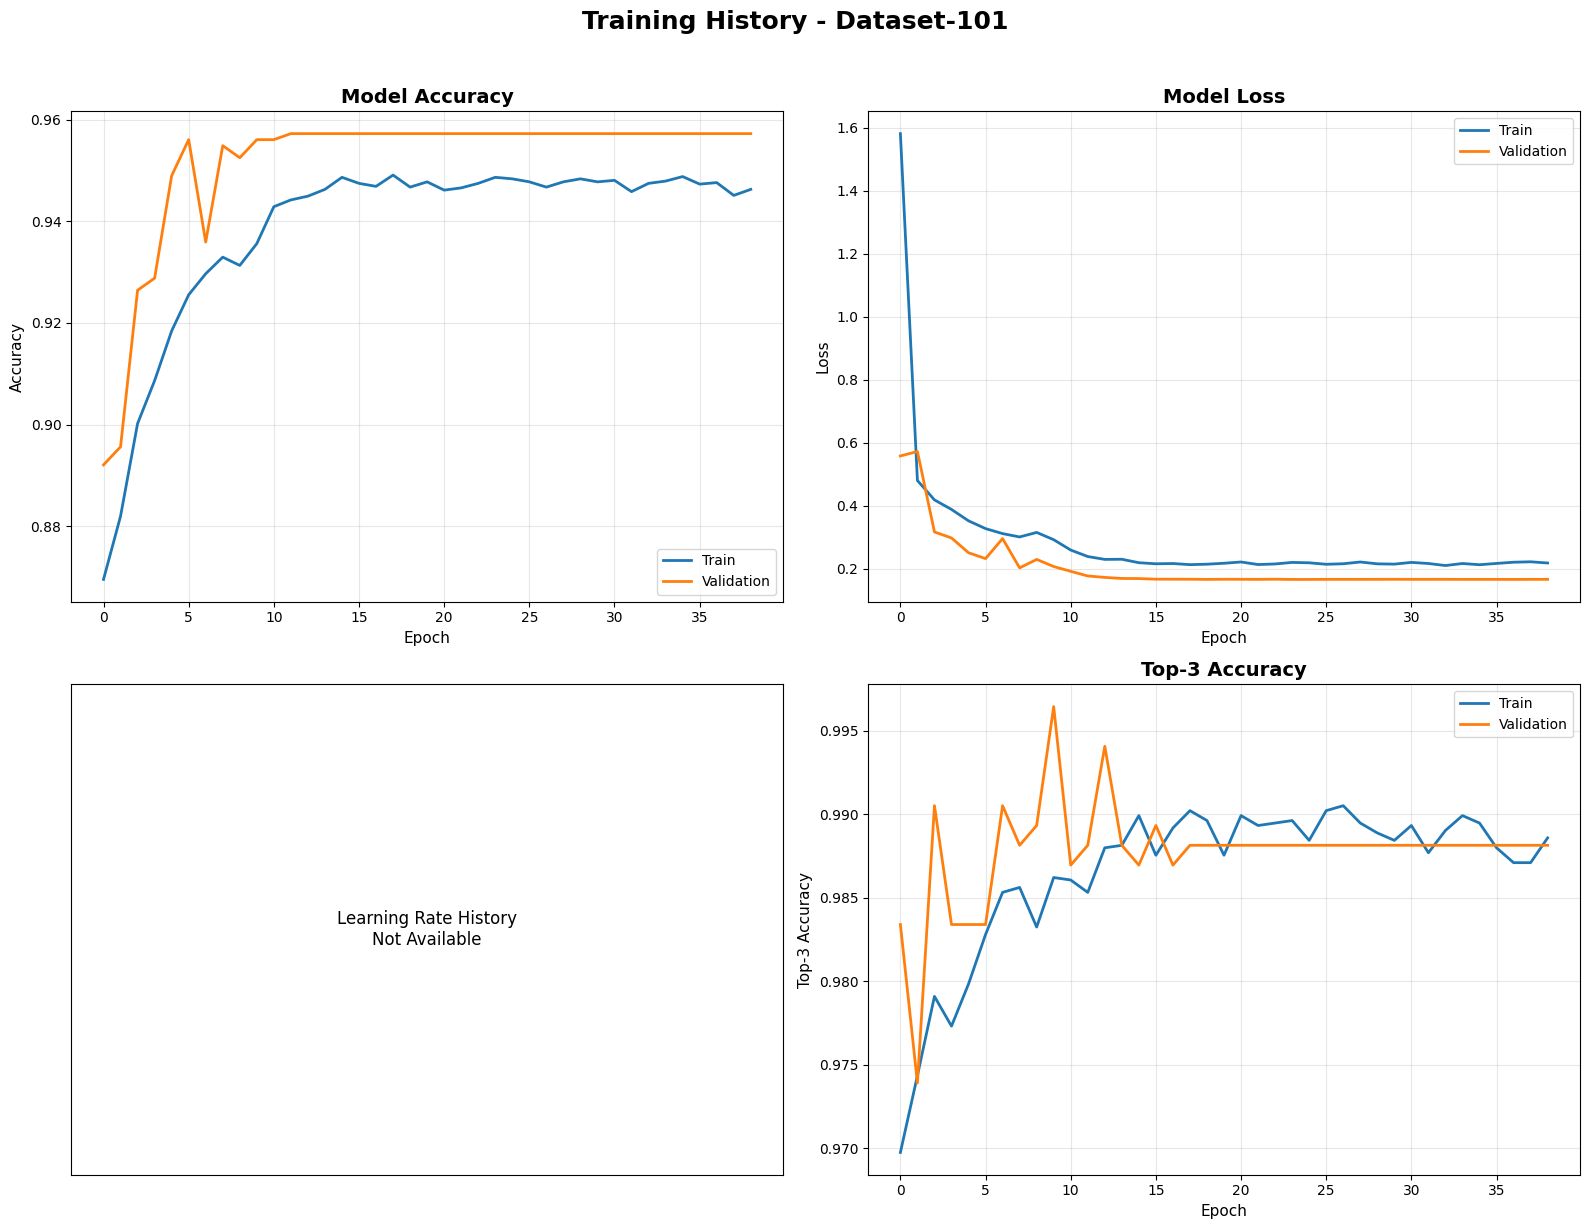

✓ Training history saved to: /content/results/training_history_dataset101.png


In [35]:
# ==============================================================================
# SECTION 14: VISUALIZATION - TRAINING HISTORY
# ==============================================================================

print("\n[3/4] Creating training history plots...")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Accuracy
axes[0, 0].plot(history.history['accuracy'], label='Train', linewidth=2)
axes[0, 0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
axes[0, 0].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch', fontsize=11)
axes[0, 0].set_ylabel('Accuracy', fontsize=11)
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(alpha=0.3)

# Loss
axes[0, 1].plot(history.history['loss'], label='Train', linewidth=2)
axes[0, 1].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[0, 1].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch', fontsize=11)
axes[0, 1].set_ylabel('Loss', fontsize=11)
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(alpha=0.3)

# Learning Rate
if 'lr' in history.history:
    axes[1, 0].plot(history.history['lr'], linewidth=2, color='orange')
    axes[1, 0].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch', fontsize=11)
    axes[1, 0].set_ylabel('Learning Rate', fontsize=11)
    axes[1, 0].set_yscale('log')
    axes[1, 0].grid(alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'Learning Rate History\nNot Available', 
                    ha='center', va='center', fontsize=12)
    axes[1, 0].set_xticks([])
    axes[1, 0].set_yticks([])

# Top-3 Accuracy
axes[1, 1].plot(history.history['top3_accuracy'], label='Train', linewidth=2)
axes[1, 1].plot(history.history['val_top3_accuracy'], label='Validation', linewidth=2)
axes[1, 1].set_title('Top-3 Accuracy', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch', fontsize=11)
axes[1, 1].set_ylabel('Top-3 Accuracy', fontsize=11)
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(alpha=0.3)

plt.suptitle(f'Training History - {DATASET_NAME}', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
history_path = f'/content/results/training_history_{DATASET_CHOICE}.png'
plt.savefig(history_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Training history saved to: {history_path}")


[4/4] Creating per-class metrics visualization...

PER-CLASS PERFORMANCE METRICS
         Class  Precision   Recall  F1-Score  Support  ROC-AUC
        ACRIMA   0.982456 1.000000  0.991150       56 0.999977
      Glaucoma   0.000000 0.000000  0.000000       21 0.916580
       ODIR-5K   0.969487 0.998571  0.983814      700 0.984016
         ORIGA   0.784615 0.980769  0.871795       52 0.994141
      cataract   0.000000 0.000000  0.000000        7 0.957109
retina_disease   0.000000 0.000000  0.000000        7 0.849966


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


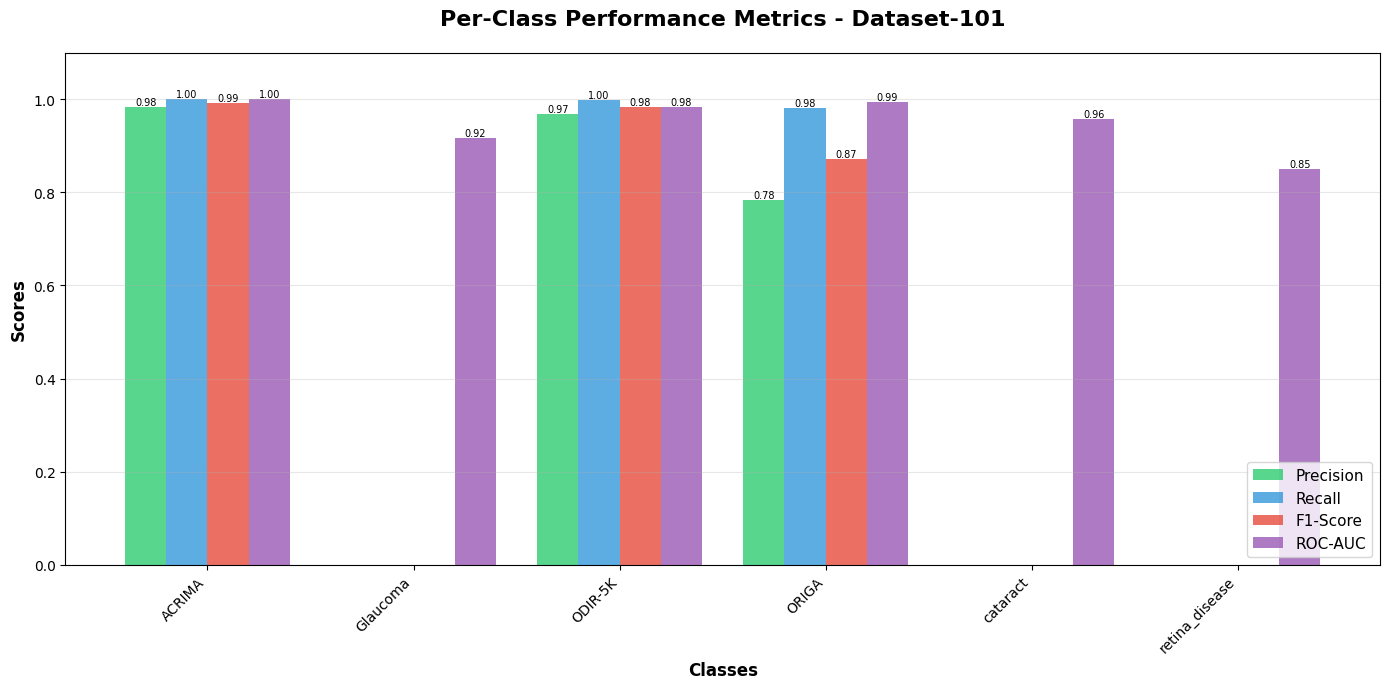


✓ Per-class metrics saved to: /content/results/per_class_metrics_dataset101.png


In [36]:
# ==============================================================================
# SECTION 15: VISUALIZATION - PER-CLASS METRICS
# ==============================================================================

print("\n[4/4] Creating per-class metrics visualization...")
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, average=None
)

# Create DataFrame
performance_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support.astype(int),
    'ROC-AUC': [roc_auc_scores.get(c, 0.0) for c in class_names]
})

print("\n" + "="*80)
print("PER-CLASS PERFORMANCE METRICS")
print("="*80)
print(performance_df.to_string(index=False))
print("="*80)

# Save to CSV
performance_df.to_csv(f'/content/results/per_class_metrics_{DATASET_CHOICE}.csv', index=False)

# Visualize
fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(class_names))
width = 0.2

bars1 = ax.bar(x - 1.5*width, precision, width, label='Precision', alpha=0.8, color='#2ecc71')
bars2 = ax.bar(x - 0.5*width, recall, width, label='Recall', alpha=0.8, color='#3498db')
bars3 = ax.bar(x + 0.5*width, f1, width, label='F1-Score', alpha=0.8, color='#e74c3c')
bars4 = ax.bar(x + 1.5*width, performance_df['ROC-AUC'], width, label='ROC-AUC', alpha=0.8, color='#9b59b6')

ax.set_xlabel('Classes', fontsize=12, fontweight='bold')
ax.set_ylabel('Scores', fontsize=12, fontweight='bold')
ax.set_title(f'Per-Class Performance Metrics - {DATASET_NAME}', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend(fontsize=11, loc='lower right')
ax.grid(alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])

# Add value labels on bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.05:  # Only show label if bar is visible
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2f}',
                   ha='center', va='bottom', fontsize=7)

plt.tight_layout()
metrics_path = f'/content/results/per_class_metrics_{DATASET_CHOICE}.png'
plt.savefig(metrics_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\n✓ Per-class metrics saved to: {metrics_path}")


SAVING RESULTS
✓ Results saved to: /content/results/evaluation_results_dataset101.json
✓ Training history saved to: /content/results/history_dataset101.csv

GENERATING SAMPLE PREDICTIONS


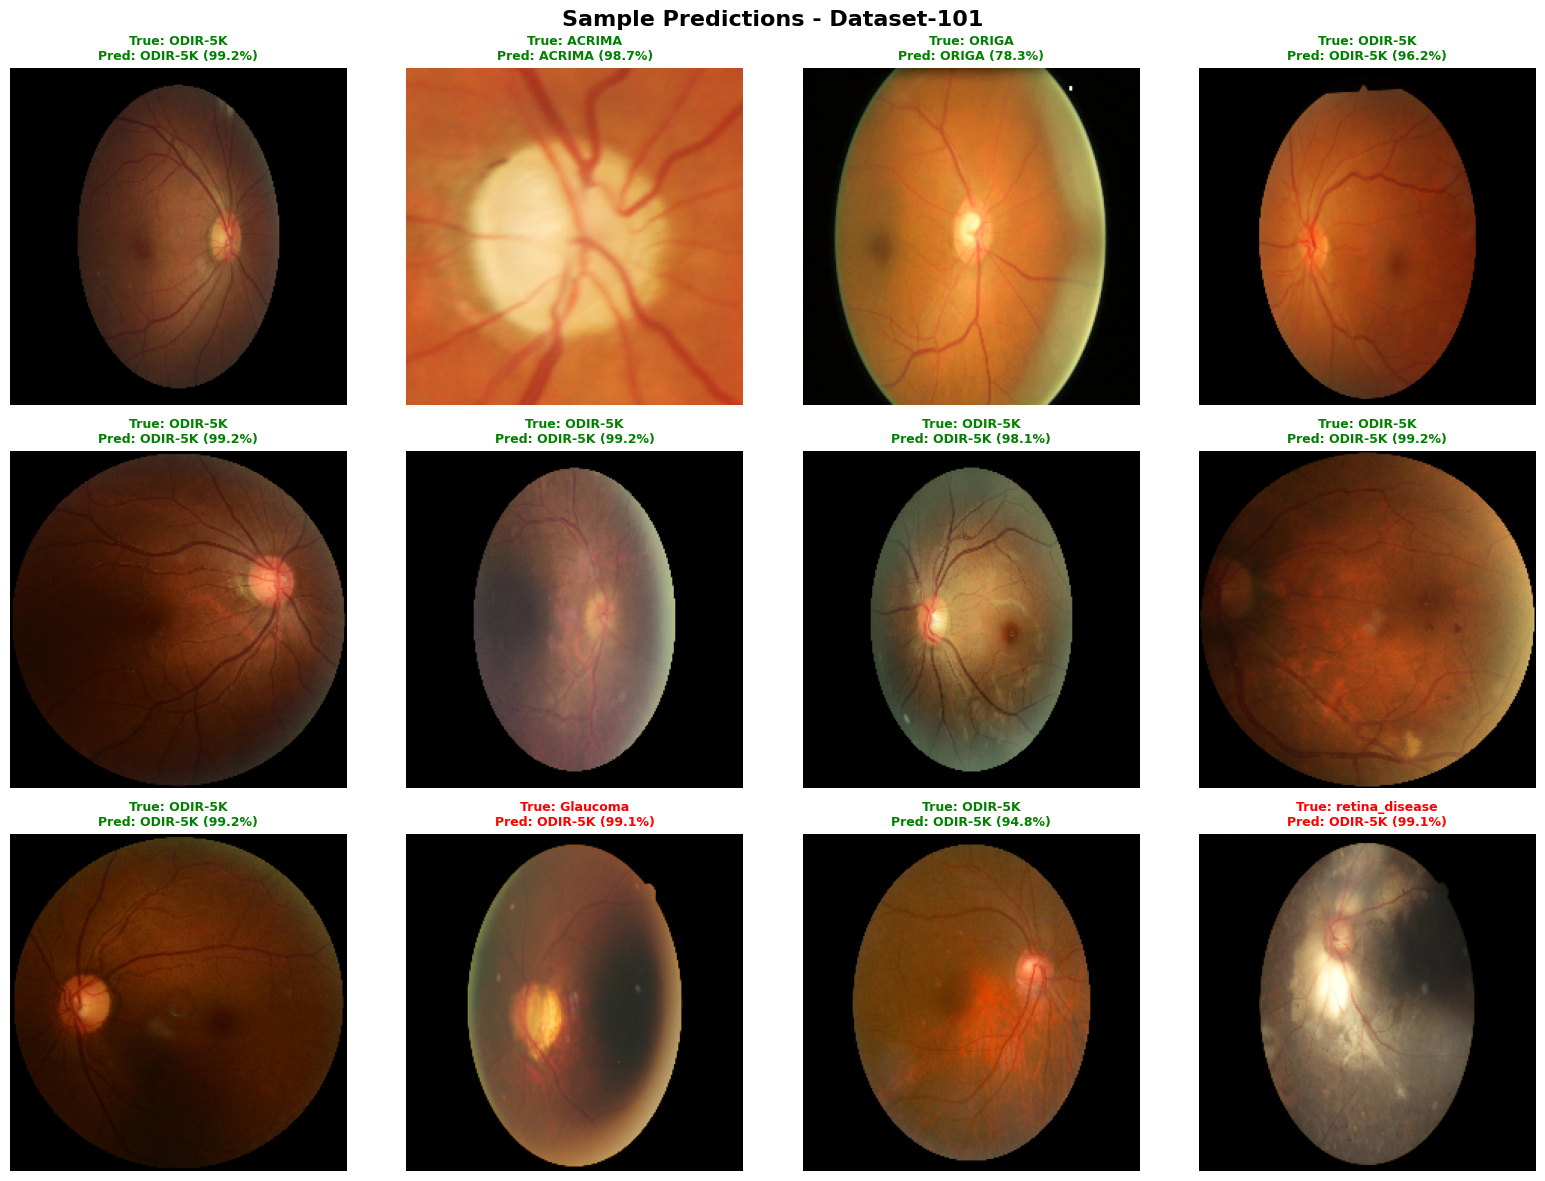

✓ Sample predictions saved to: /content/results/sample_predictions_dataset101.png

CREATING INFERENCE PIPELINE
✓ Inference pipeline created

Testing inference on sample image...

Sample Prediction for: 3225_right.jpg
--------------------------------------------------
1. ODIR-5K: 99.19%
2. cataract: 0.31%
3. Glaucoma: 0.26%
--------------------------------------------------

FINAL SUMMARY

📊 Dataset: Dataset-101
   Classes: 6
   Total Images: 8429

🔧 Model Configuration:
   Architecture: Enhanced Multi-Stage with Attention
   Total Parameters: 7,914,628
   Model Size: 30.19 MB

📈 Performance Metrics:
   Test Accuracy: 95.61%
   Test Loss: 0.1889
   Top-3 Accuracy: 98.46%

💾 Saved Files:
   Models:
   - Best: /content/models/best_model_dataset101.h5
   - Final: /content/models/final_model_dataset101.h5
   - Weights: /content/models/final_weights_dataset101.h5

   Results:
   - Confusion Matrix: /content/results/confusion_matrix_dataset101.png
   - ROC Curves: /content/results/roc_curves_

In [37]:
# ==============================================================================
# SECTION 16: SAVE COMPREHENSIVE RESULTS
# ==============================================================================

print("\n" + "="*80)
print("SAVING RESULTS")
print("="*80)

# Compile all results
results = {
    'dataset': DATASET_NAME,
    'dataset_choice': DATASET_CHOICE,
    'num_classes': len(class_names),
    'class_names': class_names,
    'data_split': {
        'train': len(X_train_paths),
        'validation': len(X_val_paths),
        'test': len(X_test_paths)
    },
    'model_info': {
        'total_parameters': int(total_params),
        'trainable_parameters': int(trainable_params),
        'model_size_mb': float(total_params * 4 / (1024**2))
    },
    'test_results': {
        'loss': float(test_loss),
        'accuracy': float(test_acc),
        'top3_accuracy': float(test_top3)
    },
    'per_class_metrics': performance_df.to_dict('records'),
    'confusion_matrix': cm.tolist(),
    'training_config': {
        'batch_size': BATCH_SIZE,
        'image_size': IMG_SIZE,
        'initial_lr': 0.001,
        'optimizer': 'Adam',
        'loss_function': 'SparseCategoricalCrossentropy',
        'label_smoothing': 0.1,
        'epochs_trained': len(history.history['loss'])
    }
}

# Save as JSON
results_json_path = f'/content/results/evaluation_results_{DATASET_CHOICE}.json'
with open(results_json_path, 'w') as f:
    json.dump(results, f, indent=4)
print(f"✓ Results saved to: {results_json_path}")

# Save training history
history_df = pd.DataFrame(history.history)
history_csv_path = f'/content/results/history_{DATASET_CHOICE}.csv'
history_df.to_csv(history_csv_path, index=False)
print(f"✓ Training history saved to: {history_csv_path}")

# ==============================================================================
# SECTION 17: SAMPLE PREDICTIONS VISUALIZATION
# ==============================================================================

print("\n" + "="*80)
print("GENERATING SAMPLE PREDICTIONS")
print("="*80)

# Visualize some test predictions
num_samples = min(12, len(X_test_paths))
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

sample_indices = np.random.choice(len(X_test_paths), num_samples, replace=False)

for idx, ax in enumerate(axes):
    if idx < num_samples:
        # Load image
        img_path = X_test_paths[sample_indices[idx]]
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, (224, 224))
        
        # Predict
        img_normalized = img_resized / 255.0
        pred_probs = best_model.predict(np.expand_dims(img_normalized, 0), verbose=0)[0]
        pred_class = np.argmax(pred_probs)
        true_class = y_test[sample_indices[idx]]
        
        # Plot
        ax.imshow(img_resized)
        
        # Title with prediction
        color = 'green' if pred_class == true_class else 'red'
        title = f'True: {class_names[true_class]}\n'
        title += f'Pred: {class_names[pred_class]} ({pred_probs[pred_class]:.1%})'
        ax.set_title(title, fontsize=9, color=color, fontweight='bold')
        ax.axis('off')
    else:
        ax.axis('off')

plt.suptitle(f'Sample Predictions - {DATASET_NAME}', fontsize=16, fontweight='bold')
plt.tight_layout()
samples_path = f'/content/results/sample_predictions_{DATASET_CHOICE}.png'
plt.savefig(samples_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Sample predictions saved to: {samples_path}")

# ==============================================================================
# SECTION 18: INFERENCE PIPELINE CLASS
# ==============================================================================

print("\n" + "="*80)
print("CREATING INFERENCE PIPELINE")
print("="*80)

class EyeDiseasePredictor:
    """Complete inference pipeline for eye disease detection"""
    
    def __init__(self, model_path, class_names):
        self.model = tf.keras.models.load_model(
            model_path,
            custom_objects={
                'ChannelAttention': ChannelAttention,
                'SpatialAttention': SpatialAttention
            }
        )
        self.class_names = class_names
        self.img_size = (224, 224)
    
    def preprocess_image(self, image_path):
        """Preprocess single image for prediction"""
        img = cv2.imread(image_path)
        if img is None:
            raise ValueError(f"Could not load image: {image_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.img_size)
        img = img / 255.0
        return np.expand_dims(img, axis=0)
    
    def predict(self, image_path, top_k=3):
        """Predict eye disease from image"""
        # Preprocess
        img = self.preprocess_image(image_path)
        
        # Predict
        predictions = self.model.predict(img, verbose=0)[0]
        
        # Get top-k predictions
        top_indices = np.argsort(predictions)[-top_k:][::-1]
        
        results = []
        for idx in top_indices:
            results.append({
                'disease': self.class_names[idx],
                'confidence': float(predictions[idx]),
                'percentage': f"{predictions[idx]*100:.2f}%"
            })
        
        return results
    
    def batch_predict(self, image_paths):
        """Predict multiple images"""
        results = []
        for path in image_paths:
            try:
                result = self.predict(path)
                results.append({'path': path, 'predictions': result})
            except Exception as e:
                results.append({'path': path, 'error': str(e)})
        return results

# Create predictor instance
predictor = EyeDiseasePredictor(best_model_path, class_names)
print("✓ Inference pipeline created")

# Test inference
print("\nTesting inference on sample image...")
test_image_path = X_test_paths[0]
prediction_result = predictor.predict(test_image_path, top_k=3)

print(f"\nSample Prediction for: {os.path.basename(test_image_path)}")
print("-" * 50)
for i, pred in enumerate(prediction_result, 1):
    print(f"{i}. {pred['disease']}: {pred['percentage']}")
print("-" * 50)

# ==============================================================================
# SECTION 19: SUMMARY REPORT
# ==============================================================================

print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"\n📊 Dataset: {DATASET_NAME}")
print(f"   Classes: {len(class_names)}")
print(f"   Total Images: {len(X_paths)}")

print(f"\n🔧 Model Configuration:")
print(f"   Architecture: Enhanced Multi-Stage with Attention")
print(f"   Total Parameters: {total_params:,}")
print(f"   Model Size: {total_params * 4 / (1024**2):.2f} MB")

print(f"\n📈 Performance Metrics:")
print(f"   Test Accuracy: {test_acc*100:.2f}%")
print(f"   Test Loss: {test_loss:.4f}")
print(f"   Top-3 Accuracy: {test_top3*100:.2f}%")

print(f"\n💾 Saved Files:")
print(f"   Models:")
print(f"   - Best: /content/models/best_model_{DATASET_CHOICE}.h5")
print(f"   - Final: /content/models/final_model_{DATASET_CHOICE}.h5")
print(f"   - Weights: /content/models/final_weights_{DATASET_CHOICE}.h5")
print(f"\n   Results:")
print(f"   - Confusion Matrix: {cm_path}")
print(f"   - ROC Curves: {roc_path}")
print(f"   - Training History: {history_path}")
print(f"   - Per-Class Metrics: {metrics_path}")
print(f"   - Sample Predictions: {samples_path}")
print(f"   - Evaluation JSON: {results_json_path}")
print(f"   - Training Log: /content/results/training_log_{DATASET_CHOICE}.csv")

print("\n" + "="*80)
print("✅ PROJECT COMPLETED SUCCESSFULLY!")
print("="*80)

# ==============================================================================
# SECTION 20: OPTIONAL - SAVE TO GOOGLE DRIVE
# ==============================================================================

print("\n" + "="*80)
print("OPTIONAL: SAVE TO GOOGLE DRIVE")
print("="*80)
print("\nUncomment the code below to save results to Google Drive:")

"""
from google.colab import drive
drive.mount('/content/drive')

# Create directory in Drive
drive_path = f'/content/drive/MyDrive/eye_disease_detection_{DATASET_CHOICE}'
!mkdir -p "{drive_path}"
!mkdir -p "{drive_path}/models"
!mkdir -p "{drive_path}/results"

# Copy files
!cp /content/models/* "{drive_path}/models/"
!cp /content/results/* "{drive_path}/results/"

print(f"✓ All files saved to: {drive_path}")
"""

# ==============================================================================
# SECTION 21: DOWNLOAD RESULTS (OPTIONAL)
# ==============================================================================

print("\n" + "="*80)
print("OPTIONAL: DOWNLOAD RESULTS")
print("="*80)
print("\nUncomment the code below to download individual files:")

"""
from google.colab import files

# Download best model
files.download(f'/content/models/best_model_{DATASET_CHOICE}.h5')

# Download results JSON
files.download(f'/content/results/evaluation_results_{DATASET_CHOICE}.json')

# Download visualizations
files.download(f'/content/results/confusion_matrix_{DATASET_CHOICE}.png')
files.download(f'/content/results/roc_curves_{DATASET_CHOICE}.png')
files.download(f'/content/results/training_history_{DATASET_CHOICE}.png')
"""

print("\n" + "="*80)
print("🎉 ALL DONE! Ready for deployment or further experimentation.")
print("="*80)